# Journal Profiles — An Integrated FAIR, Funder, Notebook & Author View (2011–2025)

> **Research question:** Every other notebook in this project takes one *topic* (DAS category,
> ethics, gender, mandates, reproducibility, ...) and looks at it across the whole corpus. This
> notebook flips that: it takes **the journal** as the unit of analysis and asks, for every
> journal, what does its overall FAIR-data-sharing profile look like across several dimensions
> at once — data-sharing score, DAS category mix, notebook-sharing culture, funder landscape, and
> author/gender composition?

This is a synthesis notebook, not a replacement for the topic-first ones — where it reimplements
a signal that another notebook already computes in more depth (notebook-sharing detection from
`05_notebooks_in_das.ipynb`, first-author gender inference from `06_gender_analysis.ipynb`), it
uses a **simplified, single-layer version** just for journal-level aggregation; see those two
notebooks for the authoritative, fully-layered versions of each signal.

| Section | Content |
|---|---|
| 0 | Setup, master frame |
| 1 | Journal landscape overview (how many journals, how concentrated is the corpus) |
| 2 | Data-sharing score league table by journal |
| 3 | DAS category composition & restrictive-sharing rate by journal |
| 4 | Notebook-sharing rate by journal |
| 5 | Funder landscape by journal |
| 6 | Author count & first-author gender composition by journal |
| 7 | Cross-metric correlations at the journal level |
| 8 | Composite journal data-sharing-culture index |
| 9 | Statistical summary, key findings, and exports |

---

In [1]:
import importlib.util, subprocess, sys

# A bare `pip install ...` here resolves to whatever `pip` is first on
# $PATH, not this kernel's own interpreter -- in this environment that is
# a separate, PEP-668 "externally managed" pip that refuses to run at all,
# even when every package below is already installed in this kernel's own
# venv. Check first, and if actually needed, install via
# `sys.executable -m pip` so it always targets this kernel's environment
# instead of whatever's on PATH.
_required = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy', 'gender-guesser', 'names-dataset']
_import_name = {'gender-guesser': 'gender_guesser', 'names-dataset': 'names_dataset'}
_missing = [pkg for pkg in _required
            if importlib.util.find_spec(_import_name.get(pkg, pkg.replace("-", "_"))) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *_missing])
else:
    print("Required packages already installed.")

Required packages already installed.


## 0 · Setup

In [2]:
import sqlite3, re, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from pathlib import Path

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=1.15)
PALETTE   = sns.color_palette("tab10")
FAIR_YEAR = 2016
FIG_W, FIG_H = 13, 5
MIN_N = 50   # minimum articles per journal for a journal to appear in any league table

DB_PATH = Path("../data/processed/pmc_fair.db")
assert DB_PATH.exists(), f"Database not found: {DB_PATH}"

FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SAVEFIG_KWARGS = dict(dpi=150, bbox_inches="tight")

con = sqlite3.connect(DB_PATH)
con.row_factory = sqlite3.Row

def q(sql, params=()):
    """Run a query and return a DataFrame."""
    return pd.read_sql_query(sql, con, params=params)

# `article.year` is precomputed by pipeline/derive_year.py -- this notebook just reads it.
assert 'year' in {r[1] for r in con.execute("PRAGMA table_info(article)").fetchall()}, \
    "article.year not found -- run `python pipeline/derive_year.py --db <path>` first"

tables = {r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table'").fetchall()}
HAS_FUNDER = "article_funder" in tables
print(f"Funder data (Stage 6): {'yes' if HAS_FUNDER else 'no'}")

Funder data (Stage 6): yes


In [3]:
# ── Master frame: one row per article, core data-sharing/DAS signal ─────────
df = q("""
    SELECT a.article_id, a.year AS year, a.journal_id,
           j.title AS journal_title, j.publisher,
           dc.primary_category AS category, dc.data_sharing_score,
           COALESCE(da.statement, '') AS das_text
    FROM article a
    JOIN das_category dc      ON dc.article_id = a.article_id
    JOIN journal j             ON j.journal_id  = a.journal_id
    LEFT JOIN data_availability da ON da.article_id = a.article_id
    WHERE a.year BETWEEN 2011 AND 2025
""")

RESTRICTIVE = ["available_on_request", "restricted", "no_statement"]
df["is_restrictive"] = df["category"].isin(RESTRICTIVE)
df["is_repo_named"]  = df["category"] == "repository_named"

# Simplified, single-layer notebook-sharing signal (text mention only -- see
# 05_notebooks_in_das.ipynb for the full 4-layer text/URL/supplement/code-repo version)
NB_TEXT_RE = re.compile(
    r'jupyter|\.ipynb\b|\bnbviewer\b|mybinder\.org|binder\.'
    r'|colab\.research\.google|colab\.google|\bcolab\b'
    r'|\bdeepnote\b|kaggle\.com/code|code\s+ocean|codeocean\.com'
    r'|(?:python|ipython|computational|analysis)\s+notebook', re.I)
df["has_notebook"] = df["das_text"].apply(lambda t: bool(NB_TEXT_RE.search(t)) if t else False)

print(f"Master frame: {len(df):,} articles, {df['journal_id'].nunique():,} distinct journals")

Master frame: 6,874,176 articles, 21,955 distinct journals


---
## 1 · Journal Landscape Overview

How many journals make up this corpus, and how concentrated is it — do a small number of
high-volume journals dominate, or is output spread broadly?

Distinct journals with >=1 article (2011-2025): 3,944
Share of corpus from top 10 journals   : 18.7%
Share of corpus from top 100 journals  : 46.1%
Journals with >= 50 articles (used in league tables below): 3,454


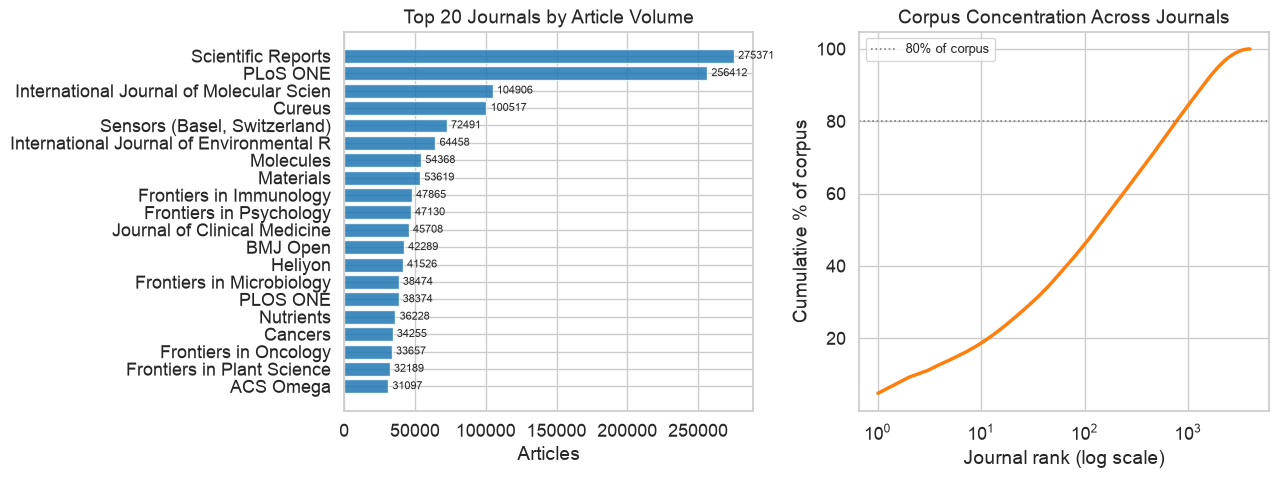

In [4]:
# ── 1.1 Article-count concentration across journals ──────────────────────────
jrnl_n = df.groupby(["journal_id", "journal_title", "publisher"]).size().reset_index(name="n")
jrnl_n = jrnl_n.sort_values("n", ascending=False).reset_index(drop=True)
jrnl_n["cum_pct"] = jrnl_n["n"].cumsum() / jrnl_n["n"].sum() * 100

n_journals = len(jrnl_n)
top10_share = jrnl_n["n"].head(10).sum() / jrnl_n["n"].sum() * 100
top100_share = jrnl_n["n"].head(100).sum() / jrnl_n["n"].sum() * 100

print(f"Distinct journals with >=1 article (2011-2025): {n_journals:,}")
print(f"Share of corpus from top 10 journals   : {top10_share:.1f}%")
print(f"Share of corpus from top 100 journals  : {top100_share:.1f}%")
print(f"Journals with >= {MIN_N} articles (used in league tables below): "
      f"{(jrnl_n['n'] >= MIN_N).sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))

ax = axes[0]
top20 = jrnl_n.head(20).copy()
top20["label"] = top20["journal_title"].fillna("(unknown)").str.slice(0, 40)
bars = ax.barh(top20["label"][::-1], top20["n"][::-1], color=PALETTE[0],
               alpha=0.85, edgecolor="white")
ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=8)
ax.set_xlabel("Articles"); ax.set_title("Top 20 Journals by Article Volume")

ax = axes[1]
ax.plot(np.arange(1, n_journals + 1), jrnl_n["cum_pct"], lw=2.5, color=PALETTE[1])
ax.axhline(80, color="grey", ls=":", lw=1.2, label="80% of corpus")
ax.set_xscale("log")
ax.set_xlabel("Journal rank (log scale)"); ax.set_ylabel("Cumulative % of corpus")
ax.set_title("Corpus Concentration Across Journals")
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_journal_01_landscape.png", **SAVEFIG_KWARGS)
plt.show()

---
## 2 · Data-Sharing Score League Table by Journal

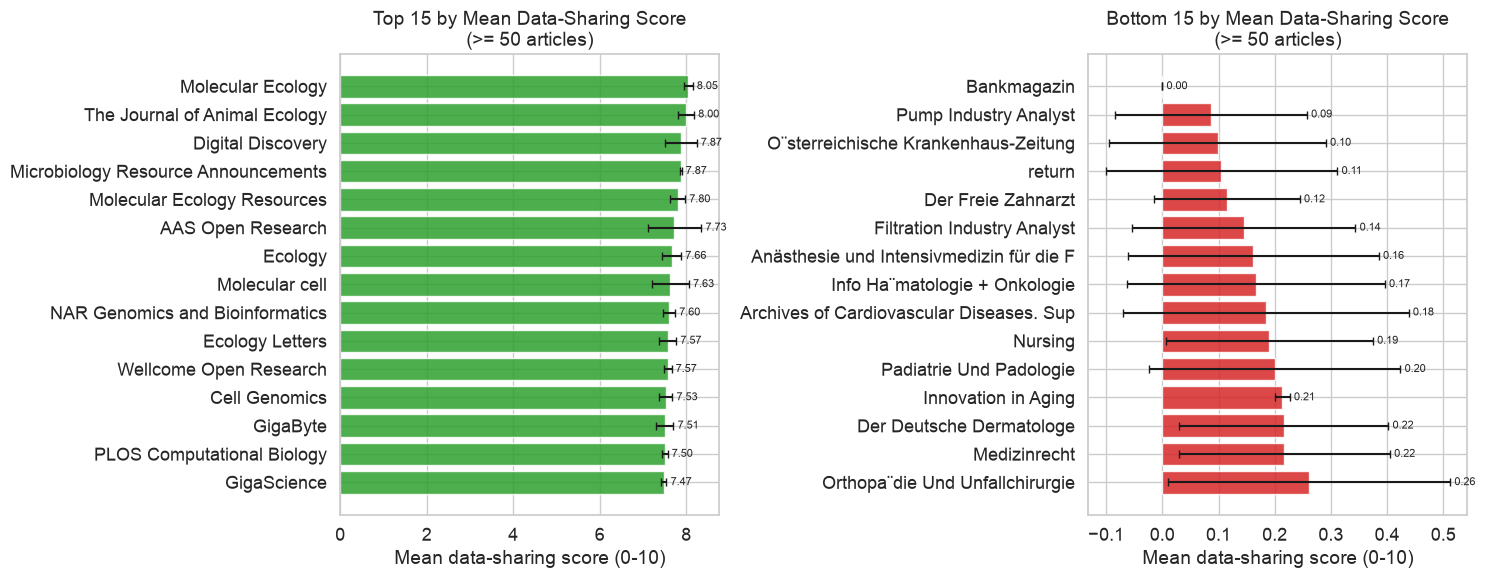

In [5]:
# ── 2.1 Mean data-sharing score per journal (n >= MIN_N) ────────────────────
jscore = (df.groupby(["journal_id", "journal_title"])["data_sharing_score"]
          .agg(n="count", mean_score="mean", std="std").reset_index())
jscore = jscore[jscore["n"] >= MIN_N].copy()
jscore["ci95"] = 1.96 * jscore["std"] / np.sqrt(jscore["n"])
jscore["label"] = jscore["journal_title"].fillna("(unknown)").str.slice(0, 40)

top15 = jscore.nlargest(15, "mean_score")
bot15 = jscore.nsmallest(15, "mean_score")

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, 6))
for ax, sub, title, clr in [(axes[0], top15, "Top 15 by Mean Data-Sharing Score", "#2ca02c"),
                             (axes[1], bot15, "Bottom 15 by Mean Data-Sharing Score", "#d62728")]:
    bars = ax.barh(sub["label"][::-1], sub["mean_score"][::-1], xerr=sub["ci95"][::-1],
                   color=clr, alpha=0.85, edgecolor="white", capsize=3)
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
    ax.set_xlabel("Mean data-sharing score (0-10)")
    ax.set_title(title + f"\n(>= {MIN_N} articles)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_journal_02_fair_league.png", **SAVEFIG_KWARGS)
plt.show()

---
## 3 · DAS Category Composition & Restrictive-Sharing Rate by Journal

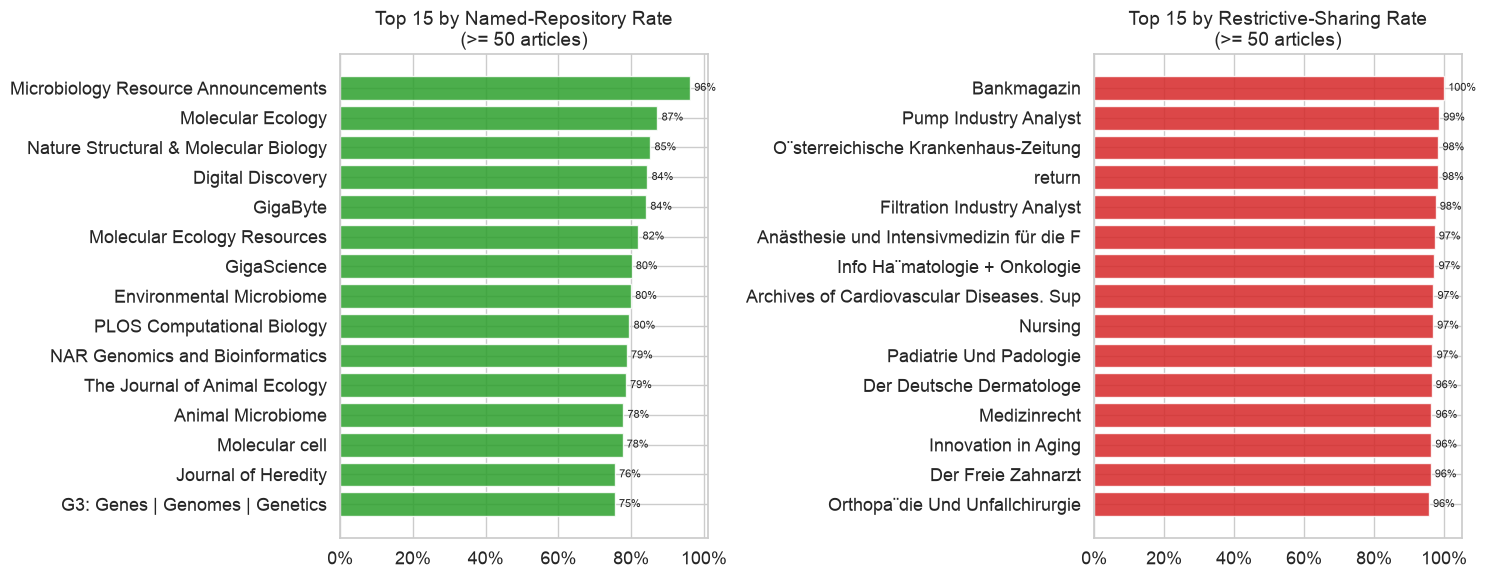

In [6]:
# ── 3.1 Named-repository rate vs restrictive-sharing rate, by journal ───────
jcat = (df.groupby(["journal_id", "journal_title"])
        .agg(n=("article_id", "count"),
             pct_repo=("is_repo_named", lambda s: s.mean() * 100),
             pct_restrictive=("is_restrictive", lambda s: s.mean() * 100))
        .reset_index())
jcat = jcat[jcat["n"] >= MIN_N].copy()
jcat["label"] = jcat["journal_title"].fillna("(unknown)").str.slice(0, 40)

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, 6))
top_repo = jcat.nlargest(15, "pct_repo")
ax = axes[0]
bars = ax.barh(top_repo["label"][::-1], top_repo["pct_repo"][::-1],
               color="#2ca02c", alpha=0.85, edgecolor="white")
ax.bar_label(bars, fmt="%.0f%%", padding=3, fontsize=8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title(f"Top 15 by Named-Repository Rate\n(>= {MIN_N} articles)")

top_restrictive = jcat.nlargest(15, "pct_restrictive")
ax = axes[1]
bars = ax.barh(top_restrictive["label"][::-1], top_restrictive["pct_restrictive"][::-1],
               color="#d62728", alpha=0.85, edgecolor="white")
ax.bar_label(bars, fmt="%.0f%%", padding=3, fontsize=8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title(f"Top 15 by Restrictive-Sharing Rate\n(>= {MIN_N} articles)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_journal_03_das_category.png", **SAVEFIG_KWARGS)
plt.show()

---
## 4 · Notebook-Sharing Rate by Journal

Simplified single-layer detection (DAS-text mention only) -- see `05_notebooks_in_das.ipynb`
for the full text/URL/supplementary-file/code-repository detection this is derived from.

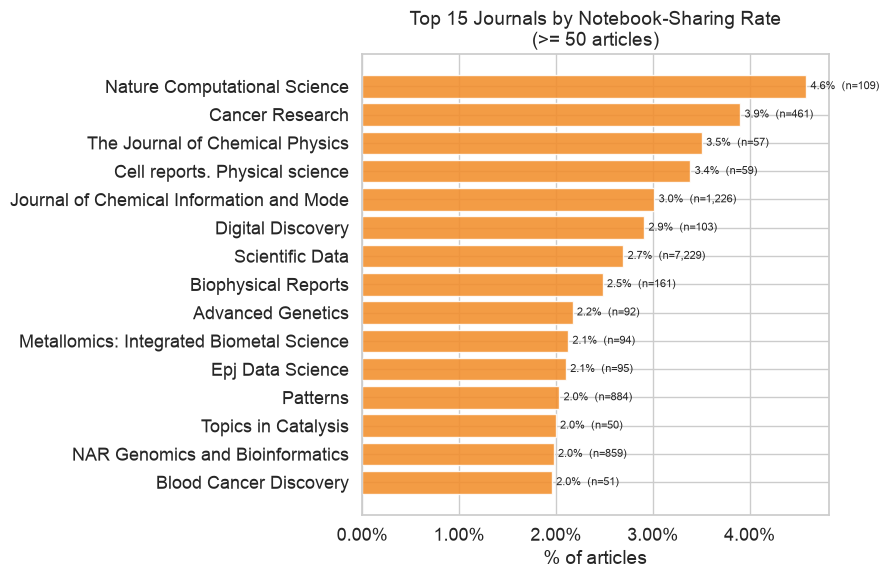

Corpus-wide notebook-sharing rate: 0.03%


In [7]:
# ── 4.1 Notebook-sharing rate by journal ─────────────────────────────────────
jnb = (df.groupby(["journal_id", "journal_title"])
       .agg(n=("article_id", "count"), pct_notebook=("has_notebook", lambda s: s.mean() * 100))
       .reset_index())
jnb = jnb[jnb["n"] >= MIN_N].copy()
jnb["label"] = jnb["journal_title"].fillna("(unknown)").str.slice(0, 40)
top15_nb = jnb.nlargest(15, "pct_notebook")

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(top15_nb["label"][::-1], top15_nb["pct_notebook"][::-1],
               color="#f28e2b", alpha=0.88, edgecolor="white")
ax.bar_label(bars, labels=[f"{v:.1f}%  (n={int(n):,})"
             for v, n in zip(top15_nb["pct_notebook"][::-1], top15_nb["n"][::-1])],
             padding=3, fontsize=8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("% of articles"); ax.set_title(f"Top 15 Journals by Notebook-Sharing Rate\n(>= {MIN_N} articles)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_journal_04_notebook_rate.png", **SAVEFIG_KWARGS)
plt.show()

print(f"Corpus-wide notebook-sharing rate: {df['has_notebook'].mean()*100:.2f}%")

---
## 5 · Funder Landscape by Journal

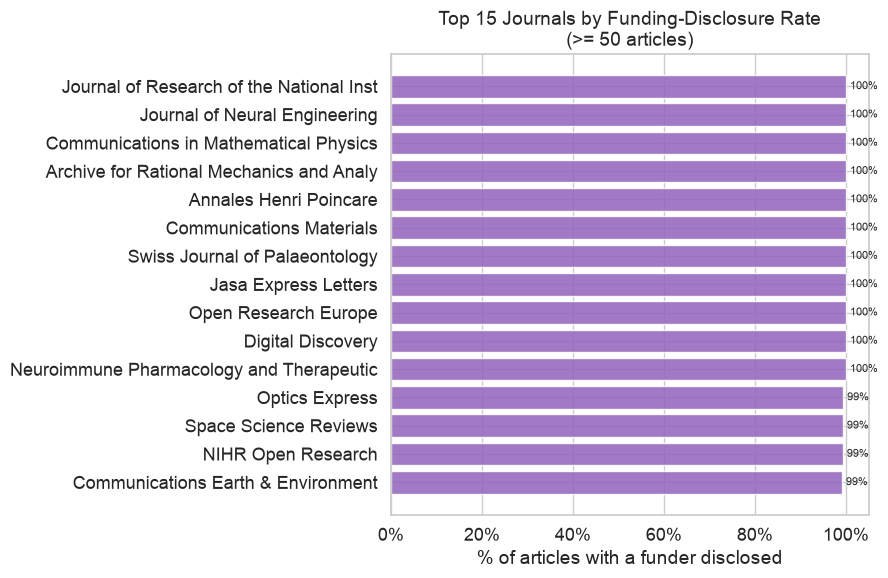

In [8]:
# ── 5.1 Funding rate and top funder per journal ──────────────────────────────
if not HAS_FUNDER:
    print("Skipped -- funder data not available in this database.")
else:
    df_fund = q("""
        SELECT af.article_id, af.funder_norm AS funder
        FROM article_funder af
        WHERE af.funder_norm != 'none'
    """)
    fund_arts = set(df_fund["article_id"])
    df["has_funder"] = df["article_id"].isin(fund_arts)

    jfund = (df.groupby(["journal_id", "journal_title"])
             .agg(n=("article_id", "count"), pct_funded=("has_funder", lambda s: s.mean() * 100))
             .reset_index())
    jfund = jfund[jfund["n"] >= MIN_N].copy()
    jfund["label"] = jfund["journal_title"].fillna("(unknown)").str.slice(0, 40)

    # top funder name per journal (by article count), for the export table
    jf = df[["article_id", "journal_id"]].merge(df_fund, on="article_id", how="inner")
    top_funder_per_journal = (jf.groupby(["journal_id", "funder"]).size()
                               .reset_index(name="n").sort_values("n", ascending=False)
                               .drop_duplicates("journal_id").set_index("journal_id")["funder"])

    top15_fund = jfund.nlargest(15, "pct_funded")
    fig, ax = plt.subplots(figsize=(9, 6))
    bars = ax.barh(top15_fund["label"][::-1], top15_fund["pct_funded"][::-1],
                   color="#9467bd", alpha=0.88, edgecolor="white")
    ax.bar_label(bars, fmt="%.0f%%", padding=3, fontsize=8)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_xlabel("% of articles with a funder disclosed")
    ax.set_title(f"Top 15 Journals by Funding-Disclosure Rate\n(>= {MIN_N} articles)")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_journal_05_funder.png", **SAVEFIG_KWARGS)
    plt.show()

---
## 6 · Author Count & First-Author Gender Composition by Journal

Simplified gender inference (first author only, same two-tier classifier as
`06_gender_analysis.ipynb`: `names_dataset` primary, `gender_guesser` fallback) -- see that
notebook for the full first/middle/last-author breakdown.

In [9]:
# ── 6.1 Author count and first-author gender, per article ───────────────────
import gender_guesser.detector as _gg_lib
from names_dataset import NameDataset as _ND

_gg = _gg_lib.Detector(case_sensitive=False)
_nd = _ND()
_CACHE = {}

def infer_gender(given_name, threshold=0.80):
    if not given_name or not str(given_name).strip():
        return "unknown"
    first = str(given_name).strip().split()[0]
    if len(first) <= 1 or (len(first) == 2 and first.endswith(".")):
        return "unknown"
    key = first.capitalize()
    if key in _CACHE:
        return _CACHE[key]
    result = "unknown"
    try:
        r = _nd.search(key)
        if r and r.get("first_name") and r["first_name"].get("gender"):
            gd = r["first_name"]["gender"]
            fp, mp = gd.get("Female", 0.0), gd.get("Male", 0.0)
            total = fp + mp
            if total > 0.01:
                fr = fp / total
                if fr >= threshold: result = "female"
                elif fr <= 1 - threshold: result = "male"
                else: result = "ambiguous"
    except Exception:
        pass
    if result == "unknown":
        GG = {"male": "male", "mostly_male": "male",
              "female": "female", "mostly_female": "female", "andy": "ambiguous"}
        result = GG.get(_gg.get_gender(key), "unknown")
    _CACHE[key] = result
    return result

df_auth = q("""
    SELECT aa.article_id, COUNT(*) AS n_authors,
           MAX(CASE WHEN aa.author_position = 1 THEN au.given_name END) AS first_given_name
    FROM article_author aa
    JOIN author au ON au.author_id = aa.author_id
    GROUP BY aa.article_id
""")

unique_names = df_auth["first_given_name"].dropna().unique()
print(f"Classifying {len(unique_names):,} unique first-author given names...")
for n in unique_names:
    infer_gender(n)
df_auth["first_author_gender"] = df_auth["first_given_name"].map(
    lambda n: infer_gender(n) if pd.notna(n) else "unknown")

df = df.merge(df_auth[["article_id", "n_authors", "first_author_gender"]],
              on="article_id", how="left")

Classifying 800,920 unique first-author given names...


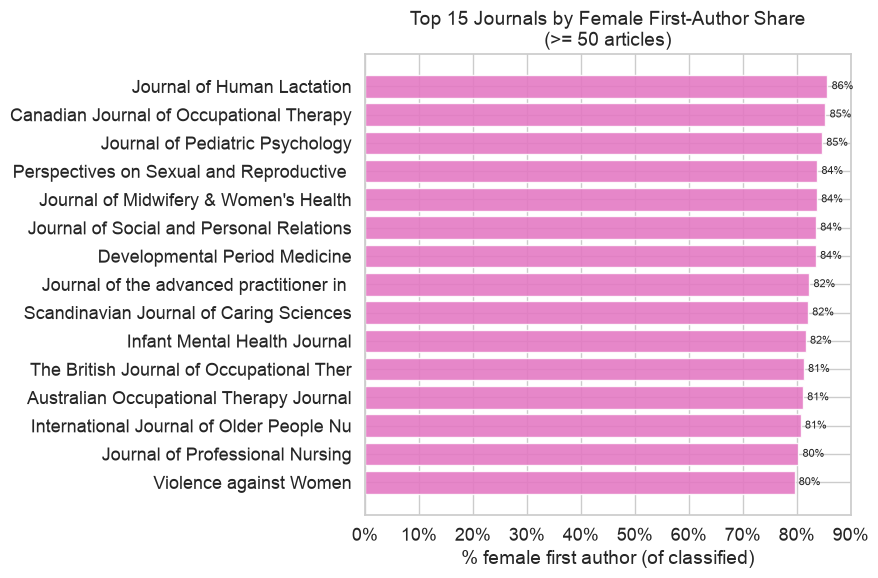

Corpus-wide: avg authors/article = 7.01, female first-author share (of classified) = 44.5%


In [10]:
# ── 6.2 Journal-level author/gender profile ──────────────────────────────────
jauth = (df.groupby(["journal_id", "journal_title"])
         .agg(n=("article_id", "count"),
              avg_authors=("n_authors", "mean"),
              pct_female_first=("first_author_gender", lambda s: (s == "female").mean() * 100),
              pct_male_first=("first_author_gender", lambda s: (s == "male").mean() * 100))
         .reset_index())
jauth = jauth[jauth["n"] >= MIN_N].copy()
jauth["label"] = jauth["journal_title"].fillna("(unknown)").str.slice(0, 40)

top15_f = jauth.nlargest(15, "pct_female_first")
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(top15_f["label"][::-1], top15_f["pct_female_first"][::-1],
               color="#e377c2", alpha=0.88, edgecolor="white")
ax.bar_label(bars, fmt="%.0f%%", padding=3, fontsize=8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("% female first author (of classified)")
ax.set_title(f"Top 15 Journals by Female First-Author Share\n(>= {MIN_N} articles)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_journal_06_gender.png", **SAVEFIG_KWARGS)
plt.show()

print(f"Corpus-wide: avg authors/article = {df['n_authors'].mean():.2f}, "
      f"female first-author share (of classified) = "
      f"{(df['first_author_gender']=='female').sum() / df['first_author_gender'].isin(['female','male']).sum() * 100:.1f}%")

---
## 7 · Cross-Metric Correlations at the Journal Level

Does a journal's notebook-sharing culture correlate with its data-sharing score? Does funding
disclosure? This treats each journal (n >= MIN_N) as one data point.

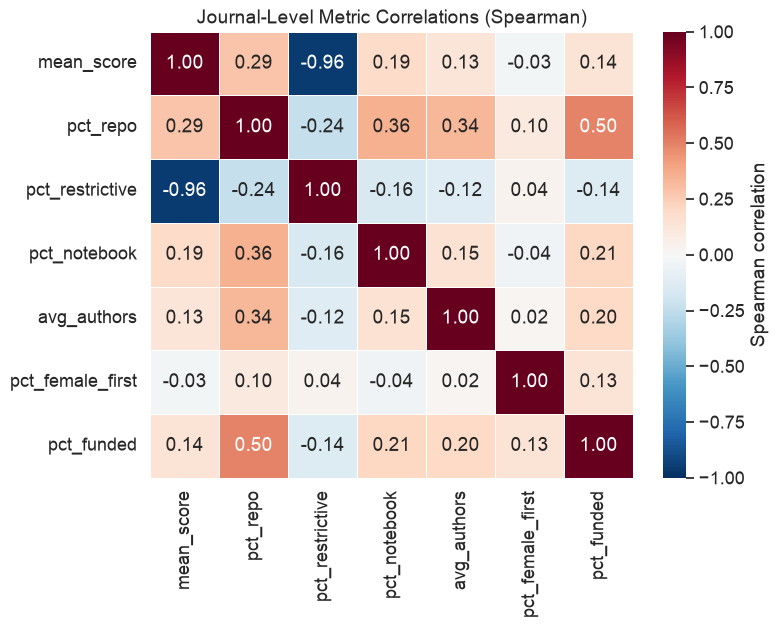

Notebook-sharing rate vs mean data-sharing score: r=0.188, p=2.78e-50, n=6,157


In [11]:
# ── 7.1 Build one row per journal with every metric, then correlate ─────────
jprofile = jscore[["journal_id", "journal_title", "n", "mean_score"]].copy()
jprofile = jprofile.merge(jcat[["journal_id", "pct_repo", "pct_restrictive"]], on="journal_id", how="left")
jprofile = jprofile.merge(jnb[["journal_id", "pct_notebook"]], on="journal_id", how="left")
jprofile = jprofile.merge(jauth[["journal_id", "avg_authors", "pct_female_first"]], on="journal_id", how="left")
if HAS_FUNDER:
    jprofile = jprofile.merge(jfund[["journal_id", "pct_funded"]], on="journal_id", how="left")

corr_cols = ["mean_score", "pct_repo", "pct_restrictive", "pct_notebook", "avg_authors", "pct_female_first"]
if HAS_FUNDER:
    corr_cols.append("pct_funded")
corr = jprofile[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax,
            linewidths=0.5, cbar_kws={"label": "Spearman correlation"})
ax.set_title("Journal-Level Metric Correlations (Spearman)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_journal_07_correlations.png", **SAVEFIG_KWARGS)
plt.show()

r, p = stats.spearmanr(jprofile["pct_notebook"], jprofile["mean_score"])
print(f"Notebook-sharing rate vs mean data-sharing score: r={r:.3f}, p={p:.2e}, n={len(jprofile):,}")

---
## 8 · Composite Journal Data-Sharing-Culture Index

A simple, transparent composite: z-score each of {mean data-sharing score, named-repository
rate, notebook-sharing rate}, then average. Not a validated instrument -- a descriptive ranking
tool for spotting journals that lead or lag across all three dimensions at once, not just one.

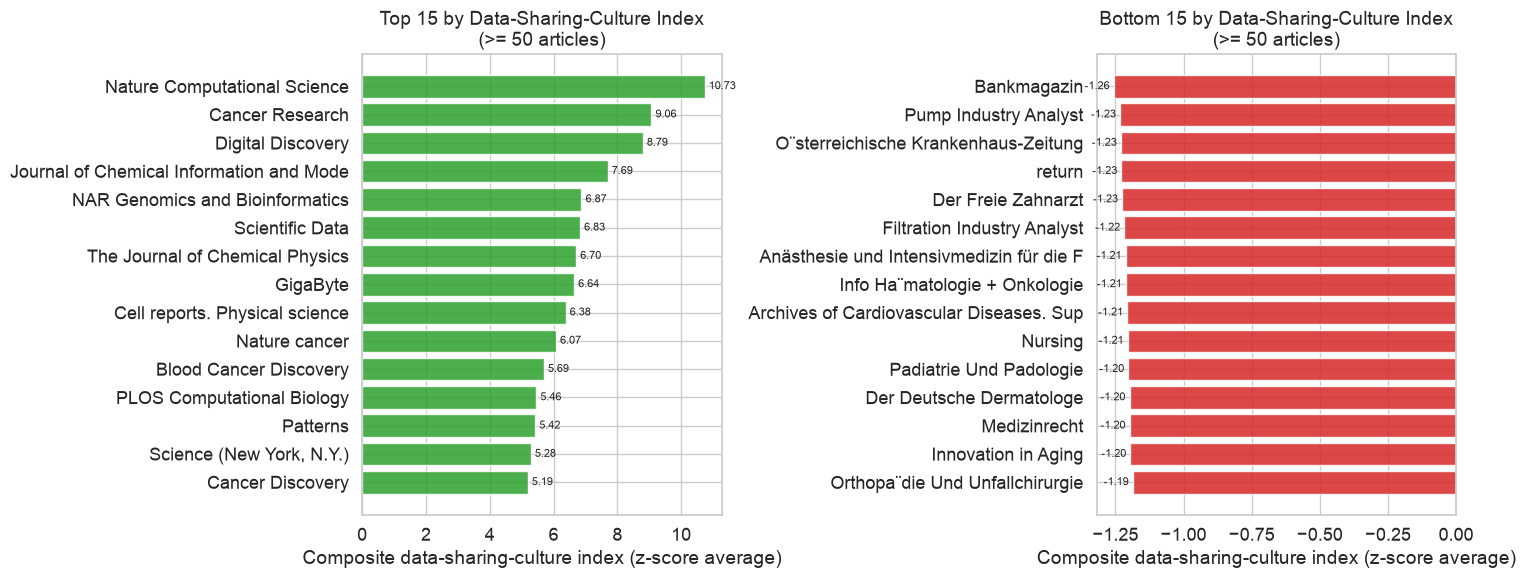

In [12]:
# ── 8.1 Composite index ──────────────────────────────────────────────────────
def zscore(s):
    return (s - s.mean()) / s.std() if s.std() > 0 else s * 0

jprofile["z_score"]   = zscore(jprofile["mean_score"])
jprofile["z_repo"]    = zscore(jprofile["pct_repo"])
jprofile["z_notebook"] = zscore(jprofile["pct_notebook"])
jprofile["data_sharing_culture_index"] = jprofile[["z_score", "z_repo", "z_notebook"]].mean(axis=1)
jprofile["label"] = jprofile["journal_title"].fillna("(unknown)").str.slice(0, 40)

top15_idx = jprofile.nlargest(15, "data_sharing_culture_index")
bot15_idx = jprofile.nsmallest(15, "data_sharing_culture_index")

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, 6))
for ax, sub, title, clr in [(axes[0], top15_idx, "Top 15", "#2ca02c"),
                             (axes[1], bot15_idx, "Bottom 15", "#d62728")]:
    bars = ax.barh(sub["label"][::-1], sub["data_sharing_culture_index"][::-1],
                   color=clr, alpha=0.85, edgecolor="white")
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
    ax.set_xlabel("Composite data-sharing-culture index (z-score average)")
    ax.set_title(f"{title} by Data-Sharing-Culture Index\n(>= {MIN_N} articles)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_journal_08_composite_index.png", **SAVEFIG_KWARGS)
plt.show()

---
## 9 · Statistical Summary, Key Findings & Exports

In [13]:
# ── 9.1 Summary ───────────────────────────────────────────────────────────────
print("=" * 70)
print("JOURNAL PROFILES -- SUMMARY")
print("=" * 70)
print(f"Distinct journals (>=1 article)      : {n_journals:,}")
print(f"Journals in league tables (>= {MIN_N})  : {len(jprofile):,}")
print(f"Top 10 journals' share of corpus      : {top10_share:.1f}%")
print(f"Corpus-wide notebook-sharing rate      : {df['has_notebook'].mean()*100:.2f}%")
if HAS_FUNDER:
    print(f"Corpus-wide funding-disclosure rate    : {df['has_funder'].mean()*100:.2f}%")
print(f"Notebook-rate vs data-sharing-score correlation : r={r:.3f} (p={p:.2e})")

JOURNAL PROFILES -- SUMMARY
Distinct journals (>=1 article)      : 3,944
Journals in league tables (>= 50)  : 6,157
Top 10 journals' share of corpus      : 18.7%
Corpus-wide notebook-sharing rate      : 0.03%
Corpus-wide funding-disclosure rate    : 33.68%
Notebook-rate vs data-sharing-score correlation : r=0.188 (p=2.78e-50)


In [14]:
# ── 9.2 Export the full journal profile table + all supporting data ─────────
export_dir = Path("../results/fair_journal_exports")
export_dir.mkdir(parents=True, exist_ok=True)

jprofile_export = jprofile.copy()
if HAS_FUNDER:
    jprofile_export["top_funder"] = jprofile_export["journal_id"].map(top_funder_per_journal)

exports = {
    "journal_article_counts.csv": jrnl_n,
    "journal_fair_score.csv": jscore,
    "journal_das_category.csv": jcat,
    "journal_notebook_rate.csv": jnb,
    "journal_author_gender.csv": jauth,
    "journal_profile_full.csv": jprofile_export,
}
if HAS_FUNDER:
    exports["journal_funder.csv"] = jfund

for fname, out_df in exports.items():
    path = export_dir / fname
    out_df.to_csv(path, index=False)
    print(f"  ✅ {path}  ({len(out_df):,} rows × {len(out_df.columns)} cols)")

print(f"\nAll exports saved to ./{export_dir}/")
print("journal_profile_full.csv is the single wide reference table -- one row per journal,")
print("every metric computed in this notebook as a column.")

  ✅ ../results/fair_journal_exports/journal_article_counts.csv  (3,944 rows × 5 cols)
  ✅ ../results/fair_journal_exports/journal_fair_score.csv  (6,157 rows × 7 cols)
  ✅ ../results/fair_journal_exports/journal_das_category.csv  (6,157 rows × 6 cols)
  ✅ ../results/fair_journal_exports/journal_notebook_rate.csv  (6,157 rows × 5 cols)
  ✅ ../results/fair_journal_exports/journal_author_gender.csv  (6,157 rows × 7 cols)
  ✅ ../results/fair_journal_exports/journal_profile_full.csv  (6,157 rows × 16 cols)
  ✅ ../results/fair_journal_exports/journal_funder.csv  (6,157 rows × 5 cols)

All exports saved to ./../results/fair_journal_exports/
journal_profile_full.csv is the single wide reference table -- one row per journal,
every metric computed in this notebook as a column.


In [15]:
con.close()
print("Database connection closed.")

Database connection closed.
